# Dataset Statistics

This page summarises the dataset collected in Milestone 1. All numbers, tables and charts below are generated by the code in this notebook.

The notebook reads the per-member summary tables in `milestone1/data/*_summary.csv` (one row per paper version), so it can be re-executed anywhere, including by GitHub Actions, without the raw crawled data.

> **Current scope:** range `2503.01914`–`2503.06913` (5,000 papers). The figures will be updated once the four members' data are merged into the final `papers` and `references` tables.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")

# Rebuild the 2503 summary from raw crawler output when it is available locally
# (raw data is never pushed to GitHub, so CI always takes the CSV branch).
RAW = Path("../../arXiv-Project/data")
SUMMARY_2503 = DATA_DIR / "arxiv_2503_summary.csv"
if RAW.exists():
    rows = []
    for d in sorted(RAW.glob("25*")):
        meta = json.loads((d / "metadata.json").read_text(encoding="utf-8"))
        refs_file = d / "references.json"
        refs = json.loads(refs_file.read_text(encoding="utf-8")) if refs_file.exists() else []
        for v in meta["versions"]:
            stamp = d / f"v{v.split('v')[-1]}" / ".complete"
            status, raw, ext = (stamp.read_text().strip().split("|") + ["", ""])[:3] if stamp.exists() else ("MISSING", "", "")
            rows.append({
                "arxiv_id": meta["arxiv_id"],
                "version": v,
                "n_versions": len(meta["versions"]),
                "n_authors": len(meta["authors"]),
                "n_refs": len(refs),
                "n_refs_arxiv": sum(r.get("ref_arxiv_id") is not None for r in refs),
                "status": status,
                "raw_bytes": int(raw.split(":")[1]) if raw else None,
                "extracted_bytes": int(ext.split(":")[1]) if ext else None,
            })
    DATA_DIR.mkdir(exist_ok=True)
    pd.DataFrame(rows).to_csv(SUMMARY_2503, index=False)

# One CSV per member range; the file name identifies the range.
frames = []
for f in sorted(DATA_DIR.glob("*_summary.csv")):
    part = pd.read_csv(f, dtype={"arxiv_id": str})
    part["range"] = f.stem.replace("_summary", "")
    frames.append(part)
df = pd.concat(frames, ignore_index=True)        # one row per version
papers = df.drop_duplicates("arxiv_id")          # one row per paper

print(f"{len(papers):,} papers | {len(df):,} versions | ranges: {', '.join(sorted(df['range'].unique()))}")

5,000 papers | 8,205 versions | ranges: arxiv_2503


## Crawling overview

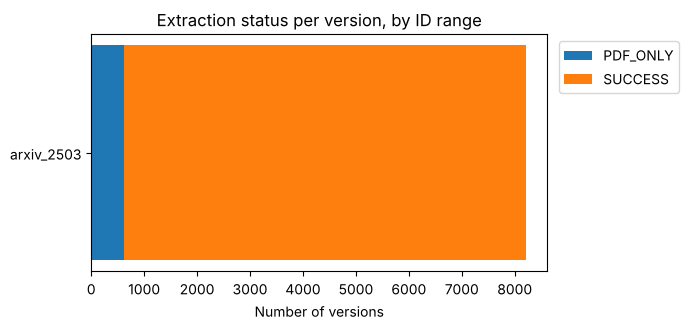

,Papers,Versions,LaTeX extracted (versions),PDF-only (versions),Success rate
range,,,,,
arxiv_2503,5000,8205,7591,614,92.5%
Total,5000,8205,7591,614,92.5%


In [2]:
status = df.groupby(["range", "status"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(7, 3 + 0.4 * len(status)))
left = np.zeros(len(status))
for col in status.columns:
    ax.barh(status.index, status[col], left=left, label=col)
    left += status[col].values
ax.set_title("Extraction status per version, by ID range")
ax.set_xlabel("Number of versions")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

overview = pd.DataFrame({
    "Papers": papers.groupby("range").size(),
    "Versions": df.groupby("range").size(),
    "LaTeX extracted (versions)": df[df["status"] == "SUCCESS"].groupby("range").size(),
    "PDF-only (versions)": df[df["status"] == "PDF_ONLY"].groupby("range").size(),
}).fillna(0).astype(int)
overview.loc["Total"] = overview.sum()
overview["Success rate"] = (overview["LaTeX extracted (versions)"] / overview["Versions"]).map("{:.1%}".format)
overview

Every paper in the range was crawled to completion: all 5,000 papers have their metadata, references and every version folder. Of the 8,205 versions, 7,591 (92.5%) contained LaTeX source that was extracted successfully. The remaining 614 versions (7.5%) are **PDF-only**: arXiv has no LaTeX source for them, so the crawler keeps an empty version folder marked `PDF_ONLY` instead of counting them as failures. 437 papers are PDF-only in every version.

## Paper size before and after removing figures

,Mean (MB),Median (MB),Total (GB)
Raw archive,4.90,1.560,37.193
.tex/.bib only,0.35,0.092,2.660


Reduction in total size: 92.8%


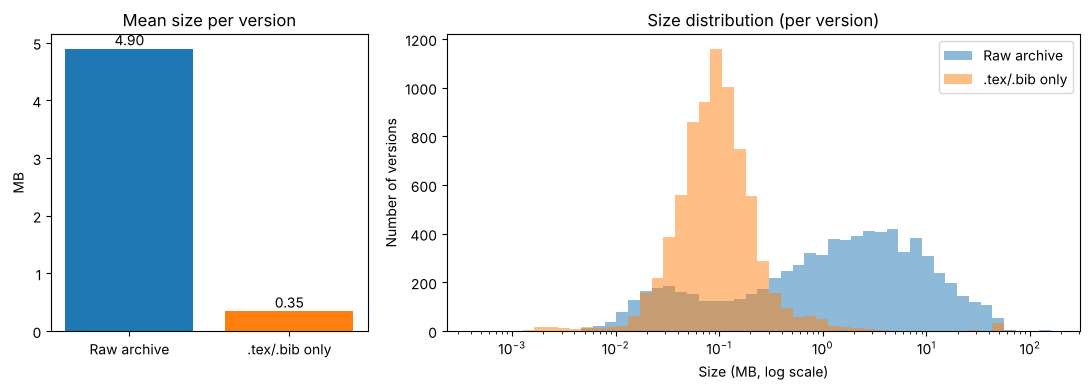

In [3]:
ok = df[df["status"] == "SUCCESS"].dropna(subset=["raw_bytes", "extracted_bytes"])
raw_mb = ok["raw_bytes"] / 1e6
ext_mb = ok["extracted_bytes"] / 1e6

size_table = pd.DataFrame({
    "Mean (MB)": [raw_mb.mean(), ext_mb.mean()],
    "Median (MB)": [raw_mb.median(), ext_mb.median()],
    "Total (GB)": [raw_mb.sum() / 1e3, ext_mb.sum() / 1e3],
}, index=["Raw archive", ".tex/.bib only"]).round(3)
display(size_table)
print(f"Reduction in total size: {1 - ext_mb.sum() / raw_mb.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(size_table.index, size_table["Mean (MB)"], color=["tab:blue", "tab:orange"])
axes[0].set_title("Mean size per version")
axes[0].set_ylabel("MB")
for x, y in enumerate(size_table["Mean (MB)"]):
    axes[0].text(x, y, f"{y:.2f}", ha="center", va="bottom")

bins = np.logspace(np.log10(ext_mb[ext_mb > 0].min()), np.log10(raw_mb.max()), 50)
axes[1].hist(raw_mb, bins=bins, alpha=0.5, label="Raw archive")
axes[1].hist(ext_mb[ext_mb > 0], bins=bins, alpha=0.5, label=".tex/.bib only")
axes[1].set_xscale("log")
axes[1].set_title("Size distribution (per version)")
axes[1].set_xlabel("Size (MB, log scale)")
axes[1].set_ylabel("Number of versions")
axes[1].legend()
plt.tight_layout()
plt.show()

Keeping only `.tex` and `.bib` files shrinks the 7,591 extracted versions from 37.2 GB to 2.7 GB, a 92.8% reduction. On average a version drops from 4.90 MB to 0.35 MB (median 1.56 MB to about 92 KB). Most of the archive size comes from figures and compiled PDFs, which are removed; the LaTeX text itself is copied unchanged, so `\includegraphics` commands and `figure` environments are kept. The small peak of raw archives around 0.02–0.3 MB corresponds to submissions with few or no figures, where filtering saves little.

*Note:* `extracted_bytes` only counts files at the top level of each version folder (the crawler measures it with `iterdir`), so papers that keep `.tex` files in subfolders are slightly under-counted.

## Version distribution

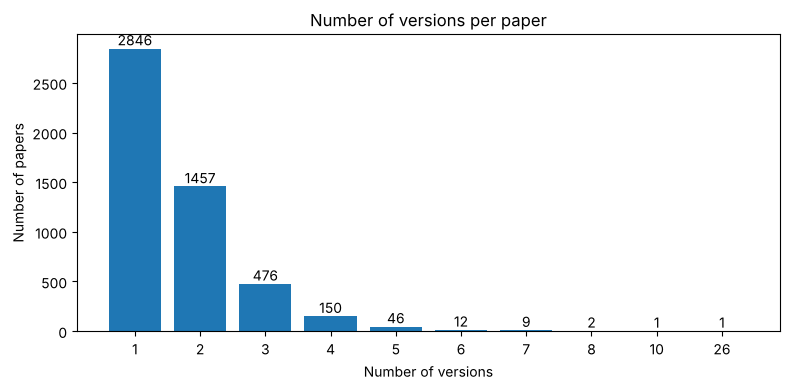

Mean versions per paper: 1.64 | papers with more than one version: 43.1% | max: 26


In [4]:
counts = papers["n_versions"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index.astype(str), counts.values)
ax.set_title("Number of versions per paper")
ax.set_xlabel("Number of versions")
ax.set_ylabel("Number of papers")
for x, y in zip(counts.index.astype(str), counts.values):
    ax.text(x, y, str(y), ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(f"Mean versions per paper: {papers['n_versions'].mean():.2f} | "
      f"papers with more than one version: {(papers['n_versions'] > 1).mean():.1%} | "
      f"max: {papers['n_versions'].max()}")

Most papers are never revised: 2,846 of the 5,000 papers (56.9%) have a single version, and the average is 1.64 versions per paper. Because the crawler downloads every version, this amounts to 8,205 source archives in total. The most revised paper, 2503.05136, has 26 versions.

## References

,Value
Papers with ≥1 reference on Semantic Scholar,94.6%
Mean references per paper,43.1
Median references per paper,38
Mean arXiv references per paper,20.0
Papers with ≥1 arXiv reference,87.4%
Share of references that have an arXiv ID,46.5%


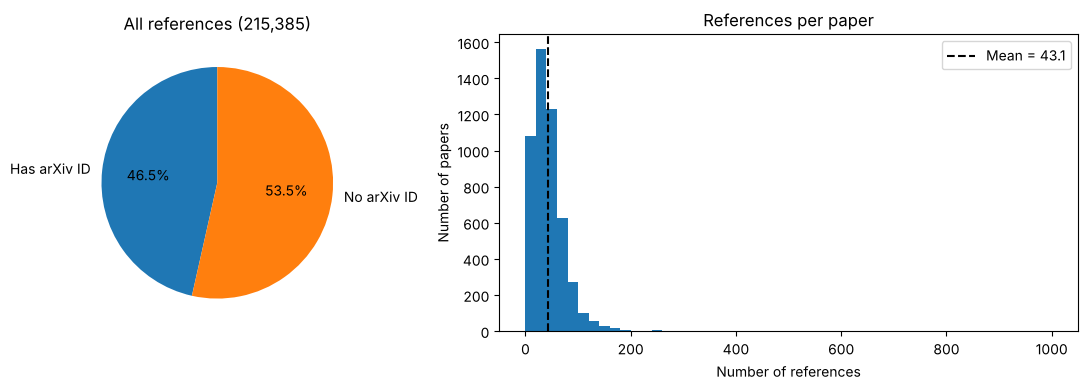

In [5]:
total_refs = papers["n_refs"].sum()
arxiv_refs = papers["n_refs_arxiv"].sum()

ref_table = pd.DataFrame({
    "Value": [
        f"{(papers['n_refs'] > 0).mean():.1%}",
        f"{papers['n_refs'].mean():.1f}",
        f"{papers['n_refs'].median():.0f}",
        f"{papers['n_refs_arxiv'].mean():.1f}",
        f"{(papers['n_refs_arxiv'] > 0).mean():.1%}",
        f"{arxiv_refs / total_refs:.1%}",
    ]
}, index=[
    "Papers with ≥1 reference on Semantic Scholar",
    "Mean references per paper",
    "Median references per paper",
    "Mean arXiv references per paper",
    "Papers with ≥1 arXiv reference",
    "Share of references that have an arXiv ID",
])
display(ref_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2]})
axes[0].pie([arxiv_refs, total_refs - arxiv_refs], labels=["Has arXiv ID", "No arXiv ID"],
            autopct="%1.1f%%", startangle=90)
axes[0].set_title(f"All references ({total_refs:,})")

axes[1].hist(papers["n_refs"], bins=50)
axes[1].axvline(papers["n_refs"].mean(), linestyle="--", color="black",
                label=f"Mean = {papers['n_refs'].mean():.1f}")
axes[1].set_title("References per paper")
axes[1].set_xlabel("Number of references")
axes[1].set_ylabel("Number of papers")
axes[1].legend()
plt.tight_layout()
plt.show()

Semantic Scholar returned references for 94.6% of the papers, with a mean of 43.1 and a median of 38 references per paper. Of all 215,385 references collected, 46.5% have an arXiv ID; these are the rows kept in the `references` table. 87.4% of the papers cite at least one other arXiv paper, 20.0 on average.

## Edge cases observed in the data

In [6]:
edge = pd.DataFrame({
    "Count": [
        int((df["status"] == "PDF_ONLY").sum()),
        int(df.groupby("arxiv_id")["status"].apply(lambda s: (s == "PDF_ONLY").all()).sum()),
        int((papers["n_refs"] == 0).sum()),
        int((papers["n_refs"] >= 1000).sum()),
        int(papers["n_versions"].max()),
    ]
}, index=[
    "PDF-only versions",
    "Papers that are PDF-only in every version",
    "Papers with no references on Semantic Scholar",
    "Papers whose reference list hits the 1,000 cap",
    "Most versions of a single paper",
])
edge

,Count
PDF-only versions,614
Papers that are PDF-only in every version,437
Papers with no references on Semantic Scholar,270
"Papers whose reference list hits the 1,000 cap",1
Most versions of a single paper,26


- **PDF-only submissions** (614 versions, 437 whole papers) have no LaTeX on arXiv. They are kept as empty `PDF_ONLY` folders so they are not re-downloaded or reported as errors.
- **Papers without references** (270, 5.4%) are most likely not yet indexed by Semantic Scholar; the crawler stores an empty `references.json` only for a definitive HTTP 404, never for a temporary error.
- **Reference lists capped at 1,000:** one paper returns exactly 1,000 references, the maximum Semantic Scholar sends in a single request, so its list is truncated.
- **Heavily revised papers:** one paper has 26 versions, all of which were downloaded and extracted.

The full list of crawler edge cases and how each is handled is described on the [Implementation](implementation.md) page.